**SAPIANS** · SCC5819 · MÓDULO 06 — PFI · MOLNAR, CAP. 23

# Quanto o preditor depende de cada entrada?

O SHAP repartia uma previsão em contribuições. A PFI faz outra pergunta:
quanto o desempenho do **mesmo modelo** muda quando perdemos a ligação de uma
entrada com o restante da ficha e com o desfecho?

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) ·
[internals](pfi_internals.ipynb) ·
[Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/06-pfi/notebooks/pfi_walkthrough.ipynb)

---

**Objetivos.** Acompanhar a permutação sem retreino; distinguir Brier, diferença
 e razão; interpretar ranking e SD; explicar permutações conjuntas e por subgrupos
sem confundi-las com causalidade ou com uma única importância verdadeira.

A aula do navegador é em inglês. O material de estudo segue em português.
As tabelas contêm os resultados reais agregados e um recorte didático real,
conferido separadamente. O recorte mostra previsões registradas do modelo fixo;
seu erro não é confundido com a importância calculada no teste completo.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import inspect
import io
import json
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import brier_score_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                        str(REPO)], check=True, capture_output=True)
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_62_pfi as P
import srag_70_explain as K
import srag_72_pfi_presentation as Q
import srag_73_teaching_demo as H

WORK = pathlib.Path(tempfile.mkdtemp(prefix="pfi-module-"))
os.chdir(WORK)
SP.aplicar()
RECORD = json.loads((REPO / "modules/00-dataset/gold/pfi_ranking.json").read_text())
SOURCE = json.loads((REPO / "modules/00-dataset/gold/pfi_slide_explainer.json").read_text())
PUBLIC = Q.project_aggregates(SOURCE)
Q.validate_aggregates(PUBLIC)
COMMITTED = json.loads((REPO / "modules/06-pfi/lecture/pfi-interactive/data/pfi-aggregates.json").read_text())
assert PUBLIC == COMMITTED
print("Origem: registros do experimento e amostra compartilhada do curso.")
print("O ranking completo é lido do registro; o modelo é reconstruído e os traços desta aula são recalculados.")
print("Projeção agregada da apresentação coincide com a fonte:", PUBLIC == COMMITTED)
print("Python:", sys.version.split()[0])

Origem: registros do experimento e amostra compartilhada do curso.
O ranking completo é lido do registro; o modelo é reconstruído e os traços desta aula são recalculados.
Projeção agregada da apresentação coincide com a fonte: True
Python: 3.12.13


## §1 — Da base ao preditor fixo

O módulo 00 é dono do Bronze, Silver, Gold, da amostra e da seleção temporal.
Este módulo reutiliza esses artefatos. A busca de modelos **não é repetida** aqui:
os cards registrados são impressos para documentar o condicionamento.
O preditor é reconstruído da amostra e só então congelado para a explicação.

O modelo de referência não usa pesos de classe nem reamostragem. A comparação
 de balanceamento é um estudo separado; não modificamos a referência nesta aula.
O teste histórico já foi observado, portanto esta explicação é exploratória.

In [3]:
protocol = RECORD["protocol"]
study = PUBLIC["study"]
for label, value in [
    ("Coorte Gold", study["cohort_n"]),
    ("Treino usado no ajuste", study["train_sample_n"]),
    ("Entradas do modelo", study["input_n"]),
    ("Fim do treino temporal", study["train_end"]),
    ("Ano da validação", study["validation_year"]),
    ("Ano do teste", study["test_year"]),
    ("Repetições por variável", protocol["repeats"]),
    ("Semente", protocol["permutation_seed"]),
]:
    print(label + ":", str(value) if "temporal" in label or label.startswith("Ano ") else SP.pt_int(value))
print("Splits registrados:")
print(SP.tabela(pd.DataFrame.from_dict(study["splits"], orient="index").reset_index(names="split"), casas=6))
print("Busca registrada por família:")
print(SP.tabela(pd.DataFrame(study["scoreboard"]), casas=6))
print("Configurações avaliadas por família:", json.dumps(study["search_counts"]))
print("Bootstrap do protocolo de desempate:", SP.pt_int(study["bootstrap_repeats"]))
print("Modelo selecionado:", study["winner"])
print("Hiperparâmetros:", json.dumps(study["xgb_params"], ensure_ascii=False))
print("Regra da escolha:", study["selection_rule"])
print("Coorte:", study["cohort_rule"])
print("Balanceamento:", study["balancing"])
print("Ausências:", study["missing"])
print("Versões do experimento:", json.dumps(protocol["versions"]))
print("AUC do teste registrado:", SP.pt(study["test_auc"], 8))
print("Brier do teste registrado:", SP.pt(study["test_brier"], 8))

gold = M.load_gold(REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet")
x, _, y = M.design_matrix(gold)
train_mask = (gold["split"] == "train").to_numpy()
test_mask = (gold["split"] == "test").to_numpy()
xe = x.loc[test_mask].reset_index(drop=True)
ye = y[test_mask]
assert dict(M.XGB_PARAMS) == protocol["xgb_params"]
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[train_mask], y[train_mask])
model_snapshot = bytes(model.get_booster().save_raw())
original_x = xe.copy(deep=True)
original_y = ye.copy()
reconstructed = P.scores(ye, model.predict_proba(xe)[:, 1])
for metric in ("brier", "auc", "logloss"):
    assert abs(reconstructed[metric] - RECORD["original"][metric]) < 5e-5
print("Treino efetivo:", SP.pt_int(train_mask.sum()))
print("Teste efetivo:", SP.pt_int(len(ye)), "; óbitos:", SP.pt_int(ye.sum()))
print("Métricas reconstruídas:", {k: SP.pt(v, 8) for k, v in reconstructed.items()})
print("Modelo fixo daqui em diante: nenhuma nova chamada de fit.")

Coorte Gold: 1.282.970
Treino usado no ajuste: 200.000
Entradas do modelo: 40
Fim do treino temporal: 2022
Ano da validação: 2023
Ano do teste: 2024
Repetições por variável: 50
Semente: 42
Splits registrados:
split letalidade_pct         n  obitos
 test      18,200000    16.142   2.945
train      31,400000 1.242.680 390.769
  val      18,900000    24.148   4.572
Busca registrada por família:
   model                    label      auc    brier
   dummy      Prevalence baseline 0,500000 0,168900
     lpm Linear probability model 0,723200 0,155200
   logit      Logistic regression 0,721400 0,154500
  arvore            Decision tree 0,704100 0,143400
floresta            Random forest 0,740300 0,145400
     xgb                  XGBoost 0,756400 0,135600
Configurações avaliadas por família: {"arvore": 24, "dummy": 1, "floresta": 10, "logit": 7, "lpm": 1, "xgb": 30}
Bootstrap do protocolo de desempate: 200
Modelo selecionado: xgb
Hiperparâmetros: {"n_estimators": 800, "max_depth": 4, "learnin

Treino efetivo: 200.000
Teste efetivo: 16.142 ; óbitos: 2.945
Métricas reconstruídas: {'brier': '0,13080778', 'logloss': '0,40901958', 'auc': '0,76444839'}
Modelo fixo daqui em diante: nenhuma nova chamada de fit.


**O que olhar.** O ano define a separação temporal. A PFI usa somente os registros
 de avaliação e o modelo já ajustado. Unknown é uma categoria preservada; não é
convertida em ausência clínica.

## §2 — O erro original: Brier

Para cada desfecho binário observado, o Brier mede o quadrado da distância entre
a probabilidade prevista e o desfecho. A média dessas perdas é o erro do conjunto:

$$E_{orig} = \frac{1}{n}\sum_{i=1}^{n}(\hat p_i-y_i)^2.$$

Uma previsão pode estar do lado errado do limiar de classificação sem ter o mesmo
 erro de outra previsão. O Brier usa a probabilidade inteira; não conta apenas
classificações erradas. É uma medida global de qualidade probabilística,
**não uma medida exclusiva de calibração**.

In [4]:
p_original = np.asarray(model.predict_proba(xe)[:, 1], dtype=np.float64)
individual_losses = (p_original - ye) ** 2
baseline = float(brier_score_loss(ye, p_original))
np.testing.assert_allclose(individual_losses.mean(), baseline, rtol=0, atol=1e-15)
print("Brier original no teste completo:", SP.pt(baseline, 8))
print("Média manual e função da biblioteca coincidem:",
      bool(np.isclose(individual_losses.mean(), baseline, atol=1e-15, rtol=0)))
print("Limite inferior do Brier binário:", SP.pt(0, 0))
print("Limite superior do Brier binário:", SP.pt(1, 0))
print("Menor Brier é melhor. A referência é compartilhada por todas as variáveis.")

Brier original no teste completo: 0,13080778
Média manual e função da biblioteca coincidem: True
Limite inferior do Brier binário: 0
Limite superior do Brier binário: 1
Menor Brier é melhor. A referência é compartilhada por todas as variáveis.


**O que olhar.** A referência é uma média do teste completo. Seu valor se repete
 nos gráficos porque o modelo e o conjunto original são os mesmos.

## §3 — Copiar, permutar, prever e restaurar

A fonte executável mora em `tools/srag_70_explain.py`, como nos outros módulos.
Mostramos o código que vai rodar: cada ordem leva valores de uma linha doadora
 para a linha receptora, mantendo alvos, índice e entradas não selecionadas.
Não retiramos uma coluna, não alteramos hiperparâmetros e não retreinamos.

A mesma coleção de ordens é usada nos experimentos separados. O experimento de
saturação **começa da matriz original**, sem carregar a idade já permutada.

In [5]:
print(inspect.getsource(K.permutar_colunas))
print(inspect.getsource(K.trace_pfi))
rng = np.random.default_rng(protocol["permutation_seed"])
orders = [rng.permutation(len(xe)) for _ in range(protocol["repeats"])]
traces = {}
for feature in ("idade_anos", "saturacao"):
    before, after = K.trace_pfi(model, xe, ye, feature, orders, brier_score_loss)
    np.testing.assert_allclose(before, baseline, rtol=0, atol=1e-15)
    stored = next(r for r in RECORD["rows"] if r["feature"] == feature)["metrics"]["brier"]
    discrepancy = float(np.max(np.abs(after - np.asarray(stored["after"]))))
    assert discrepancy < 5e-5
    traces[feature] = after
    print(feature, "; erro após médio:", SP.pt(after.mean(), 8),
          "; aumento médio:", SP.pt((after - baseline).mean(), 8),
          "; SD amostral:", SP.pt(after.std(ddof=1), 8),
          "; maior desvio do registro:", SP.pt_sig(discrepancy))
age_delta = traces["idade_anos"] - baseline
repeat_table = pd.DataFrame({
    "repetição": np.arange(1, len(orders) + 1),
    "Brier original": baseline,
    "Brier após permuta": traces["idade_anos"],
    "aumento": age_delta,
    "média acumulada": [age_delta[:k].mean() for k in range(1, len(orders) + 1)],
    "SD acumulado": [np.nan if k == 1 else age_delta[:k].std(ddof=1)
                    for k in range(1, len(orders) + 1)],
})
print("Traço completo de idade; SD de uma única repetição é indefinido:")
print(SP.tabela(repeat_table, casas=8))
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw()) == model_snapshot
print("Entradas, alvos e modelo originais preservados:", True)

def permutar_colunas(
    x_eval: pd.DataFrame,
    colunas: str | tuple[str, ...] | list[str],
    ordem,
) -> pd.DataFrame:
    """Matriz original copiada, com somente as colunas indicadas movidas.

    `ordem[i]` é a posição da linha doadora para a linha de destino `i`.
    O índice de pandas não define esse transporte: `set_axis` repõe o
    índice de destino depois da seleção posicional, preservando inclusive
    categorias nativas. A matriz recebida nunca é modificada.

    Uma coluna implementa a permutação marginal. Várias colunas recebem a
    mesma ordem, preservando as combinações/tuplas observadas entre elas. Para
    subgrupos, o chamador fornece uma bijeção cujos doadores pertencem ao
    mesmo grupo que os destinos; esta função não infere os grupos nem uma
    distribuição condicional.
    """
    selecionadas = (colunas,) if isinstance(colunas, str) else tuple(colunas)
    if not selecionadas or len(set(selecionadas)) != len(selecionadas):
        raise ValueError("Indi

idade_anos ; erro após médio: 0,15425722 ; aumento médio: 0,02344944 ; SD amostral: 0,00073672 ; maior desvio do registro: 0,00


saturacao ; erro após médio: 0,13509785 ; aumento médio: 0,00429007 ; SD amostral: 0,00032827 ; maior desvio do registro: 0,00
Traço completo de idade; SD de uma única repetição é indefinido:
repetição Brier original Brier após permuta    aumento média acumulada SD acumulado
        1     0,13080778         0,15357206 0,02276428      0,02276428           NA
        2     0,13080778         0,15512181 0,02431404      0,02353916   0,00109584
        3     0,13080778         0,15511792 0,02431014      0,02379615   0,00089363
        4     0,13080778         0,15476658 0,02395880      0,02383681   0,00073416
        5     0,13080778         0,15460160 0,02379382      0,02382822   0,00063610
        6     0,13080778         0,15527176 0,02446398      0,02393418   0,00062535
        7     0,13080778         0,15395809 0,02315031      0,02382220   0,00064317
        8     0,13080778         0,15555497 0,02474719      0,02393782   0,00067935
        9     0,13080778         0,15447597 0,023668

Entradas, alvos e modelo originais preservados: True


### Ver uma janela real da primeira permutação do teste completo

Conservamos as mesmas fichas históricas como receptores visíveis: primeiras
fichas adultas por desfecho no teste, depois na ordem original da base.
A tabela mostra idade e saturação; o modelo recebe todas as entradas originais.
O recorte selecionado pelo desfecho não representa a população do teste.

**Correção do mecanismo didático.** A ordem manual histórica trocava valores
somente entre fichas de mesmo desfecho neste recorte. Seus números permanecem
no registro para auditoria. Agora a tabela é uma janela da primeira ordem
aleatória do experimento global: os doadores vêm do teste inteiro, e não
somente das fichas visíveis. A ordem é fixada pelo protocolo antes de medir
a perda. Nenhum sorteio foi escolhido porque fez o erro subir ou cair.

As previsões originais, idades, saturação e desfechos das fichas não mudam.
As previsões permutadas mudam porque elas agora recebem os valores realmente
usados naquela repetição global. A média de perda do recorte é impressa aqui
somente para auditoria. O gráfico da apresentação usa o erro global, a primeira
repetição identificada e a média e SD de todas as repetições registradas.


In [6]:
# As mesmas fichas; nenhum índice, identificador, data ou localidade é impresso.
case_source = SOURCE["preview"]
case_threshold = float(case_source["threshold"])
case_n_per_outcome = int(case_source["selection"]["records_per_outcome"])
case_adult_min = 18
case_test_gold = gold.loc[test_mask]
case_index = pd.concat([
    case_test_gold[(case_test_gold["idade_anos"] >= case_adult_min) &
                   (case_test_gold["y_obito"] == outcome)].head(case_n_per_outcome)
    for outcome in (0, 1)
]).sort_index().index
case_x = x.loc[case_index].reset_index(drop=True)
case_y = gold.loc[case_index, "y_obito"].to_numpy()
case_x_snapshot, case_y_snapshot = case_x.copy(deep=True), case_y.copy()
case_positions = gold.loc[test_mask].index.get_indexer(case_index)
assert np.all(case_positions >= 0)
pd.testing.assert_frame_equal(xe.iloc[case_positions].reset_index(drop=True), case_x)
case_labels = list("ABCDEFGH")
assert len(case_x) == len(case_labels) == len(case_source["rows"])
case_p_original = np.asarray(model.predict_proba(case_x)[:, 1], dtype=np.float64)
np.testing.assert_array_equal(case_p_original, [row["p_original"] for row in case_source["rows"]])
for column in ("idade_anos", "saturacao"):
    np.testing.assert_array_equal(case_x[column].to_numpy(), [row[column] for row in case_source["rows"]])
np.testing.assert_array_equal(case_y, [row["y_obito"] for row in case_source["rows"]])

# O registro histórico fica intacto e suas previsões continuam reproduzíveis.
historical_order = np.asarray(case_source["permutation"], dtype=int)
historical_cross_outcome = int(np.count_nonzero(case_y[historical_order] != case_y))
assert historical_cross_outcome == 0
historical_comparison = [{"estado histórico": "Original", "Brier": float(np.mean((case_p_original - case_y) ** 2))}]
for round_ in case_source["rounds"]:
    historical_changed = K.permutar_colunas(case_x, round_["feature"], historical_order)
    historical_probability = np.asarray(model.predict_proba(historical_changed)[:, 1], dtype=np.float64)
    np.testing.assert_array_equal(historical_probability, round_["probability"])
    historical_loss = (historical_probability - case_y) ** 2
    np.testing.assert_array_equal(historical_loss, round_["individual_brier"])
    np.testing.assert_allclose(historical_loss.mean(), round_["sample_brier_mean"], rtol=0, atol=1e-15)
    historical_comparison.append({"estado histórico": round_["label"], "Brier": float(historical_loss.mean())})
print("Registro histórico preservado: nenhuma ficha, modelo ou previsão original mudou.")
print("Ordem manual histórica, base zero:", historical_order.tolist())
print("Trocas históricas entre desfechos distintos:", SP.pt_int(historical_cross_outcome))
print("Defeito: a ordem ilustrativa antiga conserva os blocos de desfecho deste recorte; não é o sorteio marginal do estudo.")
print(SP.tabela(pd.DataFrame(historical_comparison), casas=8))

# A primeira ordem GLOBAL é fixada pelo protocolo ANTES das previsões.
print(inspect.getsource(H.build_teaching_demo))
case_projection = H.build_teaching_demo(model, xe, ye, case_positions, case_source,
                                        PUBLIC["rows"], RECORD)
case_preview = case_projection["preview"]
global_first_order = orders[0]
Q.validate_teaching_records(case_projection, PUBLIC)
case_rounds = case_preview["rounds"]
case_table = pd.DataFrame(case_preview["rows"])
case_before = float(case_table["brier_original"].mean())
case_print_rows, case_comparison = [], []
for cell, label, changed in [("original", "Original", case_x)] + [
    (round_["cell"], round_["label"] + " permutada",
     K.permutar_colunas(xe, round_["feature"], global_first_order).iloc[case_positions].reset_index(drop=True)) for round_ in case_rounds
]:
    probability = case_p_original if cell == "original" else case_table["p_after_" + cell].to_numpy()
    loss = (probability - case_y) ** 2
    original_loss = case_table["brier_original"].to_numpy()
    delta = loss - original_loss
    prediction = (probability >= case_threshold).astype(int)
    case_print_rows.extend({
        "estado": label, "ficha": case_labels[i],
        "idade_anos": float(changed.iloc[i]["idade_anos"]),
        "saturacao": str(changed.iloc[i]["saturacao"]), "y_obito": int(case_y[i]),
        "p_obito": float(probability[i]), "distancia": float(abs(probability[i] - case_y[i])),
        "classe": int(prediction[i]), "acerto": bool(prediction[i] == case_y[i]),
        "erro_quadratico": float(loss[i]), "variacao_individual": float(delta[i]),
    } for i in range(len(case_x)))
    feature = None if cell == "original" else next(r["feature"] for r in case_rounds if r["cell"] == cell)
    case_comparison.append({
        "estado": label, "Brier do recorte": float(loss.mean()),
        "diferença no recorte": float(loss.mean() - case_before),
        "razão no recorte": float(loss.mean() / case_before),
        "variação relativa percentual": float((loss.mean() / case_before - 1) * 100),
        "erros de classe": int(np.count_nonzero(prediction != case_y)),
        "valores alterados": 0 if feature is None else int(np.count_nonzero(changed[feature].to_numpy() != case_x[feature].to_numpy())),
        "probabilidades alteradas": int(np.count_nonzero(probability != case_p_original)),
        "fichas com perda menor": int(np.count_nonzero(delta < 0)),
        "fichas com perda maior": int(np.count_nonzero(delta > 0)),
        "soma das melhorias": float(delta[delta < 0].sum()),
        "soma das pioras": float(delta[delta > 0].sum()),
    })
    pd.testing.assert_frame_equal(changed.drop(columns=feature) if feature else changed,
                                  case_x.drop(columns=feature) if feature else case_x)
print("Regra do recorte: primeiras fichas adultas por desfecho no teste, depois ordem original; sem seleção pela previsão ou perda.")
print("Adulto, idade mínima em anos:", SP.pt_int(case_adult_min))
print("Fichas por desfecho:", SP.pt_int(case_n_per_outcome), "; total:", SP.pt_int(len(case_x)))
print("Desfechos do recorte (0 = sobrevida; 1 = óbito):", {int(v): int(n) for v, n in zip(*np.unique(case_y, return_counts=True))})
print("Entradas do preditor:", SP.pt_int(case_x.shape[1]), "; entradas visíveis:", SP.pt_int(2))
print("Idade: dias entre nascimento e sintomas divididos por", SP.pt(365.25, 2), "; tipo original:", str(case_x["idade_anos"].dtype))
print("Limiar didático:", SP.pt(case_threshold, 2), "; classe positiva: óbito.")
print("Semente e algoritmo registrados:", SP.pt_int(case_preview["permutation_seed"]), "; numpy.default_rng().permutation")
print("Janela da repetição:", SP.pt_int(case_preview["displayed_repeat"]), "; avaliação completa:", SP.pt_int(case_preview["evaluation_n"]))
print("Escopo dos doadores:", case_preview["permutation_scope"])
print("Hash das ordens globais confere com o protocolo:", case_preview["permutation_orders_sha256"] == protocol["permutation_orders_sha256"])
print("As posições e os identificadores dos doadores não são exportados.")
print("Fichas, entradas visíveis, previsões, distâncias e perdas reais recalculadas:")
print(SP.tabela(pd.DataFrame(case_print_rows), casas=8))
print("Erro das fichas receptoras selecionadas: auditoria local desta janela, não o gráfico global.")
print(SP.tabela(pd.DataFrame(case_comparison), casas=8))
print("Previsões originais e fichas históricas conservadas exatamente:", True)
print("As novas previsões permutadas usam os doadores reais da primeira repetição global; o registro da PFI global permanece inalterado.")
print("Teste completo, média após as repetições e SD; não calculados das fichas acima:")
print(SP.tabela(pd.DataFrame([row["full_test"] for row in case_rounds]), casas=8))
global_readings = []
for round_ in case_rounds:
    feature = round_["feature"]
    registered_after = np.asarray(next(r for r in RECORD["rows"] if r["feature"] == feature)["metrics"]["brier"]["after"])
    full = round_["full_test"]
    global_readings.append({
        "entrada": round_["label"], "original global": full["before"],
        "primeira repetição global": round_["full_test_single_brier"],
        "média global das repetições": full["after_mean"],
        "SD global": full["after_sd"], "diferença global": full["difference_mean"],
        "razão global": full["ratio_mean"],
        "aumento relativo global percentual": full["relative_increase_percent"],
        "repetições globais com erro maior": int(np.count_nonzero(registered_after > full["before"])),
        "mínimo após global": float(registered_after.min()), "máximo após global": float(registered_after.max()),
    })
print("Leitura global para a apresentação, independente do erro do recorte:")
print(SP.tabela(pd.DataFrame(global_readings), casas=8))
assert "preview" not in PUBLIC
Q.validate_aggregates(PUBLIC)
pd.testing.assert_frame_equal(case_x, case_x_snapshot)
np.testing.assert_array_equal(case_y, case_y_snapshot)
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw()) == model_snapshot
print("Restauro original entre as trocas; entradas, alvos e preditor preservados:", True)
case_output = WORK / "figures_generated/pfi-teaching-records.json"
case_output.parent.mkdir(exist_ok=True)
case_output.write_text(json.dumps(case_projection, ensure_ascii=False, indent=2) + "\n")
print("Arquivo separado gerado:", case_output.name)
print("Projeção agregada continua sem preview:", "preview" not in PUBLIC)


Registro histórico preservado: nenhuma ficha, modelo ou previsão original mudou.
Ordem manual histórica, base zero: [1, 0, 3, 2, 5, 7, 4, 6]
Trocas históricas entre desfechos distintos: 0
Defeito: a ordem ilustrativa antiga conserva os blocos de desfecho deste recorte; não é o sorteio marginal do estudo.
estado histórico      Brier
        Original 0,31962453
             Age 0,31740654
      Low oxygen 0,31126673
def build_teaching_demo(
    fitted_model,
    full_inputs: pd.DataFrame,
    full_target: np.ndarray,
    receiver_positions: np.ndarray,
    historical_preview: dict,
    full_rows: list[dict],
    experiment: dict,
) -> dict:
    """Janela das mesmas fichas na primeira permutação GLOBAL registrada.

    As ordens são reproduzidas com o protocolo e conferidas pelo hash do
    estudo antes das novas previsões. Cada entrada é permutada a partir da
    matriz completa original; as trocas nunca se acumulam. Preservamos
    float32, categorias nativas, demais entradas e alvos. A

Regra do recorte: primeiras fichas adultas por desfecho no teste, depois ordem original; sem seleção pela previsão ou perda.
Adulto, idade mínima em anos: 18
Fichas por desfecho: 4 ; total: 8
Desfechos do recorte (0 = sobrevida; 1 = óbito): {0: 4, 1: 4}
Entradas do preditor: 40 ; entradas visíveis: 2
Idade: dias entre nascimento e sintomas divididos por 365,25 ; tipo original: float32
Limiar didático: 0,50 ; classe positiva: óbito.
Semente e algoritmo registrados: 42 ; numpy.default_rng().permutation
Janela da repetição: 1 ; avaliação completa: 16.142
Escopo dos doadores: full temporal test
Hash das ordens globais confere com o protocolo: True
As posições e os identificadores dos doadores não são exportados.
Fichas, entradas visíveis, previsões, distâncias e perdas reais recalculadas:
              estado ficha  idade_anos    saturacao y_obito    p_obito  distancia classe  acerto erro_quadratico variacao_individual
            Original     A 76,66255951          sim       0 0,38593900 

Restauro original entre as trocas; entradas, alvos e preditor preservados: True
Arquivo separado gerado: pfi-teaching-records.json
Projeção agregada continua sem preview: True


**O que olhar.** Cada linha da tabela é uma avaliação real do teste completo.
 A primeira permutação não é a média das repetições. A SD cresce de uma distribuição
 de perdas, não de uma coleção de novos modelos.

## §4 — Ranking, distribuição e incerteza dos embaralhamentos

O registro completo conserva cada repetição para todas as entradas. Recalculamos
 seus resumos para as métricas registradas, com direção declarada: Brier e log-loss
pioram quando aumentam; AUC piora quando diminui.

O ranking principal usa aumento médio do Brier. A caixa mostra quartis; as hastes
 azuis mostram SD. Esses elementos respondem a perguntas diferentes. A SD aqui é
amostral, condicional ao preditor e aos registros de teste: não é intervalo de
 confiança populacional, nem variabilidade entre retreinos.

Entradas conferidas: 40
Métricas conferidas: 3
Repetições em cada vetor: 50
                 entrada Brier original Brier após médio aumento médio         SD MCSE da média posição média entre sorteios SD da posição
            Idade (anos)     0,13080778       0,15425722    0,02344944 0,00073672    0,00010419                   1,00000000    0,00000000
         Saturação baixa     0,13080778       0,13509785    0,00429007 0,00032827    0,00004642                   2,00000000    0,00000000
Desconforto respiratório     0,13080778       0,13361822    0,00281044 0,00023345    0,00003302                   3,20000000    0,57142857
            Escolaridade     0,13080778       0,13320743    0,00239965 0,00022399    0,00003168                   4,40000000    0,85714286
                Dispneia     0,13080778       0,13309244    0,00228466 0,00018807    0,00002660                   4,82000000    0,87341694
               Puerpério     0,13080778       0,13293205    0,00212427 0,00011376    0,000

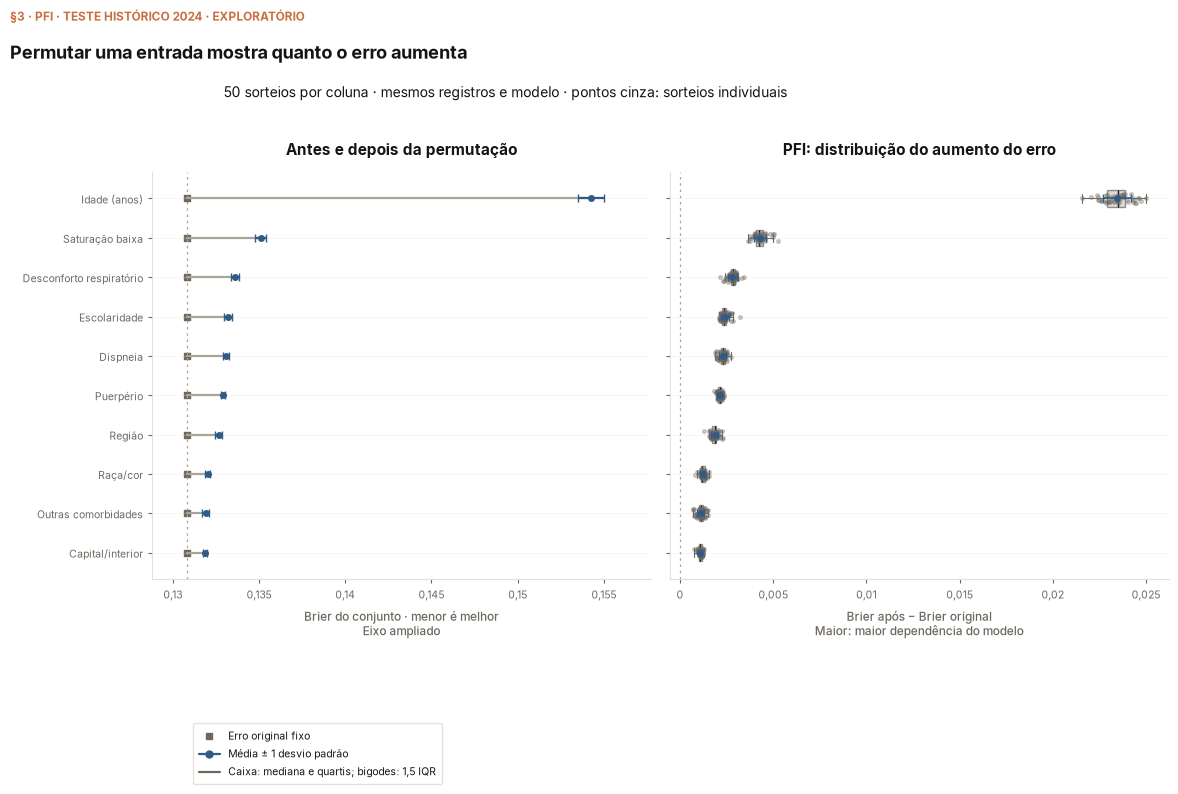

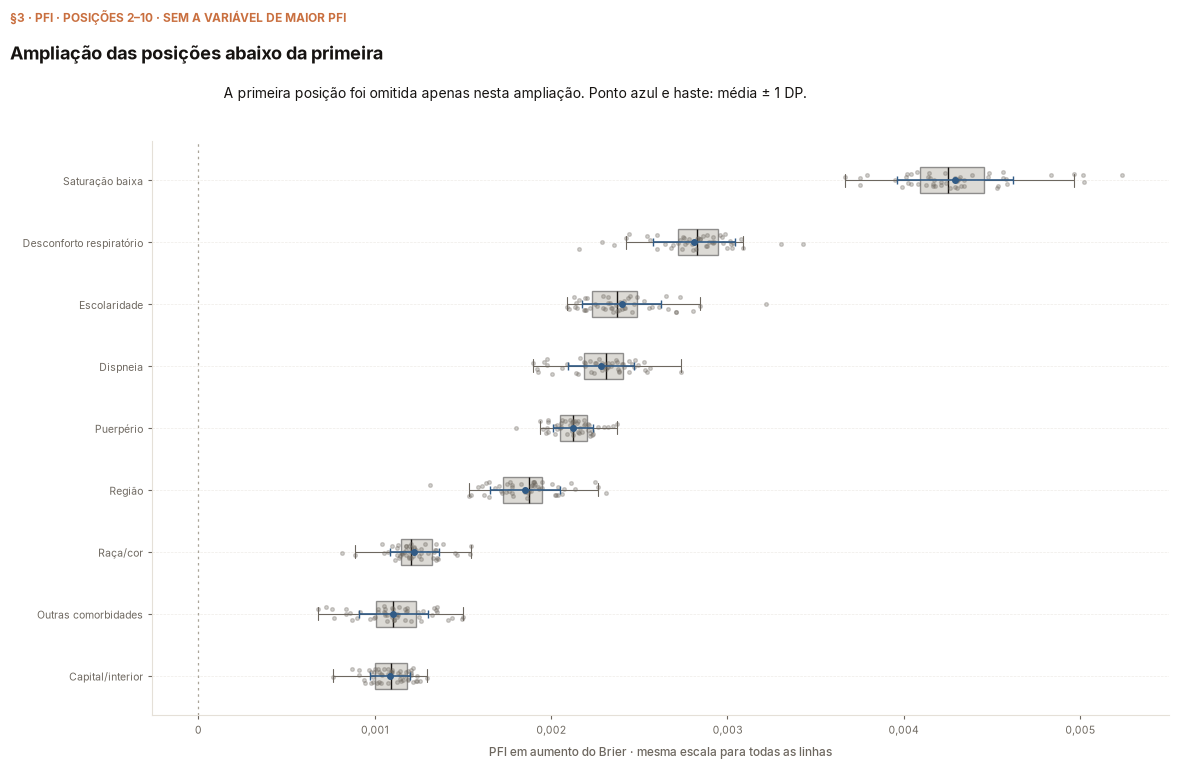

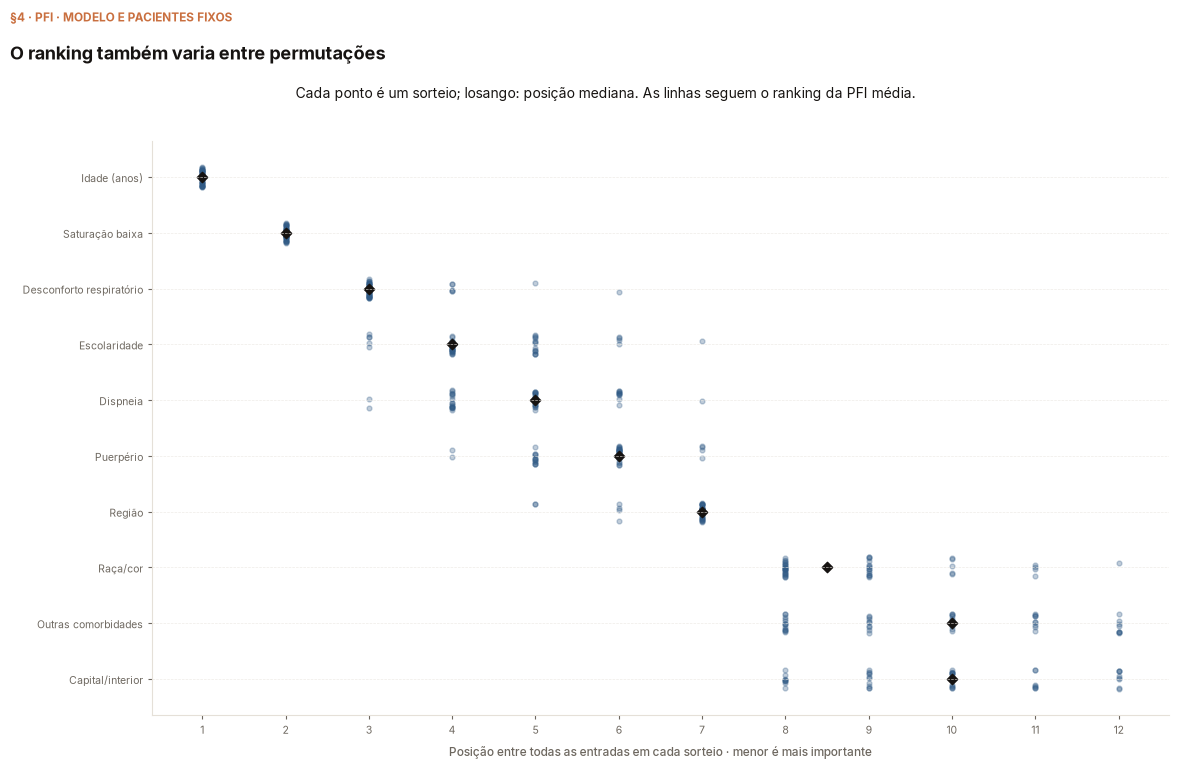

In [7]:
for row in RECORD["rows"]:
    for metric, values in row["metrics"].items():
        after = np.asarray(values["after"], dtype=np.float64)
        sign = -1 if metric == "auc" else 1
        delta = sign * (after - RECORD["original"][metric])
        np.testing.assert_allclose(delta, values["delta"], rtol=0, atol=1e-15)
        np.testing.assert_allclose(delta.mean(), values["mean"], rtol=0, atol=1e-15)
        np.testing.assert_allclose(delta.std(ddof=1), values["sd"], rtol=0, atol=1e-15)
print("Entradas conferidas:", SP.pt_int(len(RECORD["rows"])))
print("Métricas conferidas:", SP.pt_int(len(RECORD["original"])))
print("Repetições em cada vetor:", SP.pt_int(protocol["repeats"]))
top10 = sorted(RECORD["rows"], key=lambda r: r["metrics"]["brier"]["rank"])[:10]
print(SP.tabela(pd.DataFrame([{
    "entrada": r["label"],
    "Brier original": RECORD["original"]["brier"],
    "Brier após médio": r["metrics"]["brier"]["after_mean"],
    "aumento médio": r["metrics"]["brier"]["mean"],
    "SD": r["metrics"]["brier"]["sd"],
    "MCSE da média": r["metrics"]["brier"]["mcse"],
    "posição média entre sorteios": r["metrics"]["brier"]["rank_mean"],
    "SD da posição": r["metrics"]["brier"]["rank_sd"],
} for r in top10]), casas=8))
for fig in P.figures(RECORD, WORK / "figures_generated"):
    display(fig)
    plt.close(fig)

**O que olhar.** Idade lidera a média neste teste. Posições próximas podem trocar
 entre sorteios. Bigodes de boxplot não são os mesmos objetos que média ± SD.
 As figuras são regeneradas em diretório temporário; a promoção para o módulo é
 uma cópia explícita, não uma gravação silenciosa na aula.

## §5 — Diferença e razão

Com erro menor sendo melhor, Molnar permite ler a diferença
$FI_j^{diff}=E_{perm,j}-E_{orig}$ ou a razão
$FI_j^{ratio}=E_{perm,j}/E_{orig}$. A razão exige denominador positivo.
Seu ponto neutro é um, mas ela pode ficar abaixo de um se o erro diminuir após
 a permutação. A diferença correspondente será negativa.

Para estas métricas de perda com a mesma referência positiva, dividir por uma
 constante preserva a ordem das médias. Uma barra visual com outro eixo não muda
 o experimento. A razão não é porcentagem de óbitos identificados.

In [8]:
reference = RECORD["original"]["brier"]
assert reference > 0
scale_rows = []
for row in top10:
    after = np.asarray(row["metrics"]["brier"]["after"], dtype=np.float64)
    delta, ratio = after - reference, after / reference
    scale_rows.append({
        "entrada": row["label"], "diferença média": delta.mean(),
        "SD diferença": delta.std(ddof=1), "razão média": ratio.mean(),
        "SD razão": ratio.std(ddof=1),
    })
scales = pd.DataFrame(scale_rows)
np.testing.assert_array_equal(np.argsort(-scales["diferença média"]),
                              np.argsort(-scales["razão média"]))
for plot_row in PUBLIC["rows"]:
    record = next(r for r in RECORD["rows"] if r["feature"] == plot_row["feature"])
    after = np.asarray(record["metrics"]["brier"]["after"])
    np.testing.assert_allclose(plot_row["difference_mean"], (after-reference).mean(), rtol=0, atol=1e-15)
    np.testing.assert_allclose(plot_row["ratio_sd"], (after/reference).std(ddof=1), rtol=0, atol=1e-15)
print(SP.tabela(scales, casas=8))
print("Diferença neutra:", SP.pt(0, 0), "; razão neutra:", SP.pt(1, 0))
print("Ranking das médias preservado entre as escalas:", True)
print("Equações mostradas na apresentação:", PUBLIC["equations"])
print("Valores exportados para os gráficos coincidem com o registro antes do arredondamento:", True)

                 entrada diferença média SD diferença razão média   SD razão
            Idade (anos)      0,02344944   0,00073672  1,17926637 0,00563205
         Saturação baixa      0,00429007   0,00032827  1,03279675 0,00250955
Desconforto respiratório      0,00281044   0,00023345  1,02148525 0,00178472
            Escolaridade      0,00239965   0,00022399  1,01834488 0,00171238
                Dispneia      0,00228466   0,00018807  1,01746581 0,00143776
               Puerpério      0,00212427   0,00011376  1,01623962 0,00086967
                  Região      0,00185325   0,00019849  1,01416772 0,00151740
                Raça/cor      0,00122304   0,00013898  1,00934989 0,00106251
     Outras comorbidades      0,00110591   0,00019694  1,00845448 0,00150557
        Capital/interior      0,00108641   0,00011425  1,00830541 0,00087338
Diferença neutra: 0 ; razão neutra: 1
Ranking das médias preservado entre as escalas: True
Equações mostradas na apresentação: {'difference': '$FI_j = e_

**O que olhar.** Uma diferença pequena pode representar uma mudança relativa
relevante quando o erro original é pequeno. A unidade deve aparecer no eixo.
 O aumento da perda não mostra se uma feature eleva ou reduz a probabilidade de
 um paciente: PFI não é um gráfico de direção de efeito.

## §6 — Dependência: mover o par ou embaralhar dentro do grupo

O exemplo compara cardiopatia e diabetes no mesmo teste e preditor. Primeiro
 repetimos a operação marginal separadamente. No diagnóstico conjunto, ambos os
valores vêm da **mesma linha doadora**, preservando o par observado.

Na opção por subgrupos de Molnar, diabetes define os grupos e fica fixa:
cardiopatia só recebe um valor de uma linha com a mesma categoria de diabetes.
A ordem global uniforme é filtrada por grupo. Avaliamos cada grupo com o próprio
erro original e, adicionalmente, calculamos a média ponderada pelos tamanhos dos
 grupos. Isso condiciona em diabetes; não em todas as outras features.

A comparação é exploratória. Um valor conjunto maior do que a soma dos valores
individuais não comprova interação, causalidade ou redundância.

In [9]:
pair = ("cardiopati", "diabetes")
def pair_counts(frame):
    return frame.groupby(list(pair), observed=False).size().sort_index()

original_pairs = pair_counts(xe)
diabetes_values = xe["diabetes"].to_numpy()
levels = list(xe["diabetes"].cat.categories)
restricted_orders = []
for order in orders:
    donor = np.arange(len(xe))
    for level in levels:
        receivers = np.flatnonzero(diabetes_values == level)
        donors = order[diabetes_values[order] == level]
        donor[receivers] = donors
    np.testing.assert_array_equal(diabetes_values[donor], diabetes_values)
    restricted_orders.append(donor)

actual_diagnostics = {}
for key, columns, selected_orders in [
    ("cardiopati", "cardiopati", orders),
    ("diabetes", "diabetes", orders),
    ("joint", pair, orders),
    ("within", "cardiopati", restricted_orders),
]:
    before, after = K.trace_pfi(model, xe, ye, columns, selected_orders, brier_score_loss)
    stored = next(r for r in PUBLIC["dependence"]["results"] if r["key"] == key)
    discrepancy = float(np.max(np.abs(after - np.asarray(stored["after"]))))
    assert discrepancy < 5e-5
    actual_diagnostics[key] = after
    print(key, "; média do aumento:", SP.pt((after - before).mean(), 8),
          "; SD amostral:", SP.pt(after.std(ddof=1), 8),
          "; maior desvio do registro:", SP.pt_sig(discrepancy))

weighted_after = []
for order, donor in zip(orders, restricted_orders):
    joint = K.permutar_colunas(xe, pair, order)
    within = K.permutar_colunas(xe, "cardiopati", donor)
    pd.testing.assert_series_equal(pair_counts(joint), original_pairs)
    pd.testing.assert_series_equal(pair_counts(within), original_pairs)
    pd.testing.assert_series_equal(within["diabetes"], xe["diabetes"])
    p_within = np.asarray(model.predict_proba(within)[:, 1], dtype=np.float64)
    weighted_after.append(sum(
        np.mean((p_within[diabetes_values == level] - ye[diabetes_values == level]) ** 2)
        * np.sum(diabetes_values == level) / len(ye)
        for level in levels if np.any(diabetes_values == level)
    ))
np.testing.assert_allclose(weighted_after, actual_diagnostics["within"], atol=1e-15, rtol=0)
print("Pares preservados em todas as permutações conjuntas e restritas:", True)
print("Erro ponderado dos subgrupos coincide com erro completo em todas as repetições:", True)
print("Resultados agregados que alimentam a apresentação:")
diagnostic_table = pd.DataFrame([{
    "operação": r["label"], "Brier original": r["before"],
    "Brier após médio": r["after_mean"],
    "aumento médio": r["difference_mean"], "SD": r["difference_sd"],
    "aumento × 1000": r["difference_mean"] * 1000,
    "SD × 1000": r["difference_sd"] * 1000,
} for r in PUBLIC["dependence"]["results"]])
print(SP.tabela(diagnostic_table, casas=8))
print("Fator visual do gráfico:", SP.pt_int(1000))
pd.testing.assert_frame_equal(xe, original_x)
np.testing.assert_array_equal(ye, original_y)
assert bytes(model.get_booster().save_raw()) == model_snapshot
print("Modelo, matriz e alvos originais continuam preservados:", True)

cardiopati ; média do aumento: 0,00036655 ; SD amostral: 0,00005026 ; maior desvio do registro: 0,00


diabetes ; média do aumento: 0,00042273 ; SD amostral: 0,00007109 ; maior desvio do registro: 0,00


joint ; média do aumento: 0,00093953 ; SD amostral: 0,00009813 ; maior desvio do registro: 0,00


within ; média do aumento: 0,00005736 ; SD amostral: 0,00005988 ; maior desvio do registro: 0,00


Pares preservados em todas as permutações conjuntas e restritas: True
Erro ponderado dos subgrupos coincide com erro completo em todas as repetições: True
Resultados agregados que alimentam a apresentação:
                     operação Brier original Brier após médio aumento médio         SD aumento × 1000  SD × 1000
          Heart disease alone     0,13080778       0,13117433    0,00036655 0,00005026     0,36655273 0,05026247
               Diabetes alone     0,13080778       0,13123051    0,00042273 0,00007109     0,42272677 0,07109110
                Both together     0,13080778       0,13174731    0,00093953 0,00009813     0,93952887 0,09812728
Heart disease within diabetes     0,13080778       0,13086514    0,00005736 0,00005988     0,05735961 0,05987748
Fator visual do gráfico: 1.000


Modelo, matriz e alvos originais continuam preservados: True


**O que olhar.** Mover o par preserva sua distribuição conjunta, mas pode romper
relações com outras entradas. Restringir o embaralhamento a subgrupos preserva a
categoria de diabetes de cada receptor. As duas operações mudam a pergunta.

## §7 — O que o livro diz e o que esta aula estabelece

Molnar descreve a PFI como deterioração do desempenho de um modelo fixo após
permutar uma entrada. O capítulo destaca dependência, extrapolação, importância
condicional e o caminho por subgrupos. Nesta aula seguimos o procedimento por
subgrupos para diabetes; a permutação conjunta é um diagnóstico complementar.

O registro completo evita chamar um exemplo isolado de importância média. A
 referência fixa explica o SD original nulo entre sorteios; isso não elimina
incerteza na população, no ajuste ou no transporte temporal. A quantidade de
repetições é uma escolha de protocolo, não uma demonstração de convergência.

O Brier responde à qualidade das probabilidades. AUC e outros escores podem
produzir ordens diferentes. Não trocamos de métrica depois de olhar o ranking
para obter uma história mais favorável.

In [10]:
# A saída distribuível é sempre uma projeção explícita, nunca o JSON inteiro.
Q.validate_aggregates(PUBLIC)
exported = WORK / "figures_generated/pfi-aggregates.json"
exported.write_text(json.dumps(PUBLIC, ensure_ascii=False, indent=2) + "\n")
print("Apresentação usa resultados agregados do teste completo e uma demonstração real separada com ordem sorteada.")
print("Ranking completo veio do registro; os traços de idade, saturação e dependência foram recalculados.")
print("Exportação agregada validada, sem preview de pacientes:", "preview" not in PUBLIC)
print("Arquivos gerados fora da árvore versionada:", not WORK.is_relative_to(REPO))

Apresentação usa resultados agregados do teste completo e uma demonstração real separada com ordem sorteada.
Ranking completo veio do registro; os traços de idade, saturação e dependência foram recalculados.
Exportação agregada validada, sem preview de pacientes: True
Arquivos gerados fora da árvore versionada: True


## §8 — A mesma PFI vista por Brier, log loss e AUC

A pergunta da aula pode mudar sem alterar o preditor nem suas previsões. Recalculamos os resumos e os rankings a partir dos escores registrados em cada permutação, sem escolher novos pacientes ou ordens. Brier e log loss são perdas: maior após embaralhar significa pior desempenho. AUC é um escore de discriminação: menor após embaralhar significa pior desempenho. Orientamos todas as diferenças para que importância positiva signifique piora.

As grandezas têm escalas distintas. Comparamos posições e a mensagem preditiva, sem equiparar o tamanho bruto de uma diferença de Brier a uma de log loss ou AUC. A dispersão continua sendo a dos embaralhamentos, condicionada ao modelo e ao conjunto avaliados.


Modelo, teste e ordens de permutação: os mesmos do experimento registrado.
Registros: 16.142 ; óbitos: 2.945
Entradas: 40 ; repetições por entrada: 50
Brier/log loss: diferença = após - original; AUC: diferença = original - após.
SD amostral entre permutações; modelo e registros fixos, sem reamostragem.
 métrica         entrada   original primeira após média após diferença orientada         SD posição repetições piores razão perdas aumento relativo %
   Brier    Idade (anos) 0,13080778    0,15357206 0,15425722          0,02344944 0,00073672       1                50   1,17926637        17,92663726
   Brier Saturação baixa 0,13080778    0,13485074 0,13509785          0,00429007 0,00032827       2                50   1,03279675         3,27967477
Log loss    Idade (anos) 0,40901958    0,49139918 0,49365325          0,08463367 0,00265889       1                50   1,20691838        20,69183838
Log loss Saturação baixa 0,40901958    0,42044029 0,42116321          0,01214364 0,00088863    

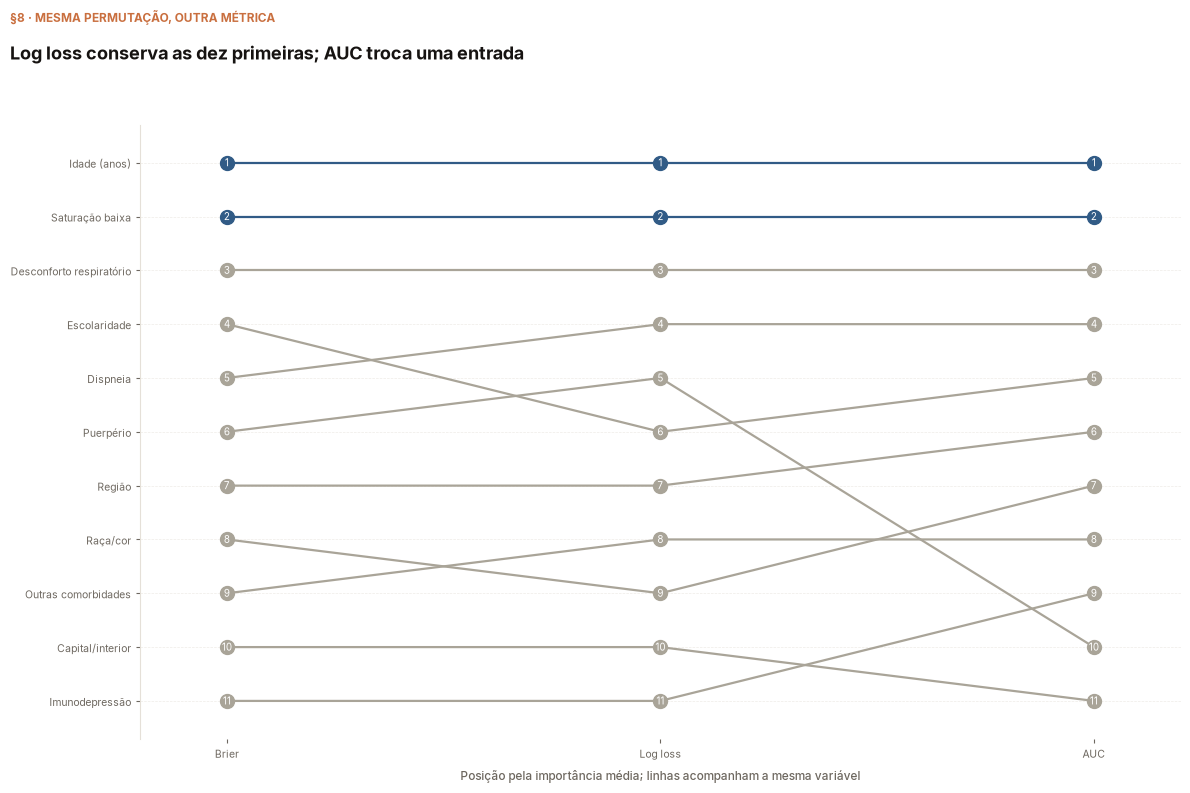

figura: figures_generated/metricas-idade-saturacao.png


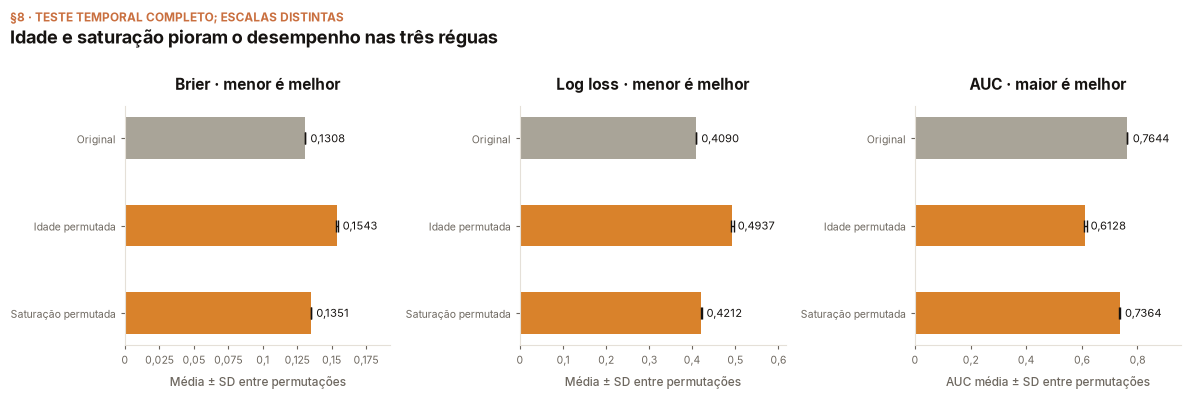

In [11]:
import srag_74_metric_comparison as MC
comparison = MC.compare_record(RECORD)
by_feature = {row["feature"]: row for row in comparison["features"]}
print("Modelo, teste e ordens de permutação: os mesmos do experimento registrado.")
print("Registros:", SP.pt_int(protocol["n_evaluation"]), "; óbitos:", SP.pt_int(protocol["events"]))
print("Entradas:", SP.pt_int(len(by_feature)), "; repetições por entrada:", SP.pt_int(protocol["repeats"]))
print("Brier/log loss: diferença = após - original; AUC: diferença = original - após.")
print("SD amostral entre permutações; modelo e registros fixos, sem reamostragem.")
summary_table = pd.DataFrame([{
    "métrica": MC.LABELS[metric], "entrada": by_feature[feature]["label"],
    "original": values["before"], "primeira após": values["first_after"],
    "média após": values["after_mean"], "diferença orientada": values["importance_mean"],
    "SD": values["importance_sd"], "posição": values["rank"],
    "repetições piores": values["worse_repeats"],
    "razão perdas": values.get("ratio_of_means", np.nan),
    "aumento relativo %": values.get("relative_increase_percent", np.nan),
} for metric in MC.METRICS for feature in ("idade_anos", "saturacao")
for values in [by_feature[feature]["metrics"][metric]]])
print(SP.tabela(summary_table, casas=8))
rank_table = pd.DataFrame([{
    "entrada": row["label"], **{MC.LABELS[m]: row["metrics"][m]["rank"] for m in MC.METRICS}
} for row in sorted(comparison["features"], key=lambda row: row["metrics"]["brier"]["rank"])])
print("Ranking completo calculado pela diferença média orientada:")
print(SP.tabela(rank_table, casas=0))
print("Concordância dos rankings nas entradas completas:")
print(SP.tabela(pd.DataFrame(comparison["agreement"])[["left", "right", "spearman", "top10_common"]], casas=8))
for feature in ("idade_anos", "saturacao", "capital_interior", "imunodepre"):
    row = by_feature[feature]
    print(row["label"], "; presença no top dez:", "; ".join(
        f'{MC.LABELS[m]} {SP.pt_int(row["metrics"][m]["top10_repeats"])}/{SP.pt_int(protocol["repeats"])}'
        for m in MC.METRICS))
for feature in ("idade_anos", "saturacao"):
    for metric in MC.METRICS:
        values = by_feature[feature]["metrics"][metric]
        assert values["worse_repeats"] == protocol["repeats"]
        assert len(set(values["rank_repeats"])) == 1
print("Idade e saturação: posições constantes em todas as repetições nas métricas comparadas.")
print("Doses antes dos sintomas: perguntas diferentes nas mesmas previsões.")
print(SP.tabela(pd.DataFrame([{
    "métrica": MC.LABELS[m], **{k: by_feature["n_doses_antes_do_sintoma"]["metrics"][m][k]
    for k in ("before", "after_mean", "importance_mean", "importance_sd", "rank", "worse_repeats", "better_repeats")}
} for m in MC.METRICS]), casas=8))

fig, ax = plt.subplots(figsize=SP.PAINEL)
selected = sorted(comparison["features"], key=lambda row: row["metrics"]["brier"]["rank"])[:11]
for row in selected:
    ranks = [row["metrics"][m]["rank"] for m in MC.METRICS]
    ax.plot(range(3), ranks, color=SP.AZUL if row["feature"] in {"idade_anos", "saturacao"} else SP.CINZA_CLARO,
            marker="o", linewidth=1.6, markersize=10)
    for j, rank in enumerate(ranks):
        ax.text(j, rank, SP.pt_int(rank), ha="center", va="center", color=SP.PAPEL, fontsize=7)
ax.set_xticks(range(3), [MC.LABELS[m] for m in MC.METRICS])
ax.set_yticks(range(1,12), [row["label"] for row in selected])
ax.set_ylim(11.7, .3)
ax.set_xlim(-.2, 2.2)
ax.set_xlabel("Posição pela importância média; linhas acompanham a mesma variável")
ax.grid(axis="x", visible=False)
ax.spines[["top", "right", "bottom"]].set_visible(False)
SP.titulo(fig, "Log loss conserva as dez primeiras; AUC troca uma entrada", "§8 · mesma permutação, outra métrica")
SP.salvar(fig, "metricas-ranking", ticks_pt=False)
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1,3, figsize=SP.FAIXA)
for ax, metric in zip(axes, MC.METRICS):
    values = [comparison["original"][metric]] + [by_feature[f]["metrics"][metric]["after_mean"] for f in ("idade_anos", "saturacao")]
    deviations = [0.] + [by_feature[f]["metrics"][metric]["after_sd"] for f in ("idade_anos", "saturacao")]
    ax.barh([2,1,0], values, color=[SP.CINZA_CLARO,SP.AMBAR,SP.AMBAR], height=.48)
    ax.errorbar(values, [2,1,0], xerr=deviations, fmt="none", ecolor=SP.ESCURO, capsize=4, linewidth=1)
    for y, value in zip([2,1,0],values):
        ax.text(value+max(values)*.025,y,SP.pt(value,4),va="center",fontsize=8)
    ax.set_yticks([2,1,0],["Original", "Idade permutada", "Saturação permutada"])
    ax.set_xlim(0,max(values)*1.25)
    ax.set_title(MC.LABELS[metric]+(" · menor é melhor" if metric!="auc" else " · maior é melhor"))
    ax.set_xlabel("Média ± SD entre permutações" if metric!="auc" else "AUC média ± SD entre permutações")
    ax.grid(axis="y",visible=False)
SP.titulo(fig,"Idade e saturação pioram o desempenho nas três réguas", "§8 · teste temporal completo; escalas distintas")
SP.salvar(fig,"metricas-idade-saturacao")
display(fig)
plt.close(fig)


**O que olhar.** O gráfico de posições compara a mesma variável entre as réguas. O gráfico antes/depois mostra o escore original e a média das permutações, com seu desvio padrão, em eixos próprios. A troca da métrica não mudou probabilidades nem decisões de classe.

### Conferir também o exemplo final de dependência

A importância conjunta e a permutação dentro dos estados de diabetes respondem a perguntas diferentes. Reavaliamos essas mesmas operações com as perdas e com AUC antes de recomendar a migração da aula. Não chamamos a diferença conjunta de efeito causal ou interação isolada.


Exemplo final: mesmas operações e mesmas ordens; mudamos apenas o escore.
                     operação  métrica diferença orientada         SD média após
                  Cardiopatia    Brier          0,00036655 0,00005026 0,13117433
                  Cardiopatia Log loss          0,00183720 0,00015314 0,41085678
                  Cardiopatia      AUC          0,00028524 0,00027183 0,76416315
                     Diabetes    Brier          0,00042273 0,00007109 0,13123051
                     Diabetes Log loss          0,00131653 0,00018326 0,41033611
                     Diabetes      AUC          0,00147567 0,00036641 0,76297272
                Both together    Brier          0,00093953 0,00009813 0,13174731
                Both together Log loss          0,00362043 0,00027092 0,41264000
                Both together      AUC          0,00229601 0,00052645 0,76215239
Heart disease within diabetes    Brier          0,00005736 0,00005988 0,13086514
Heart disease within diabetes Log l

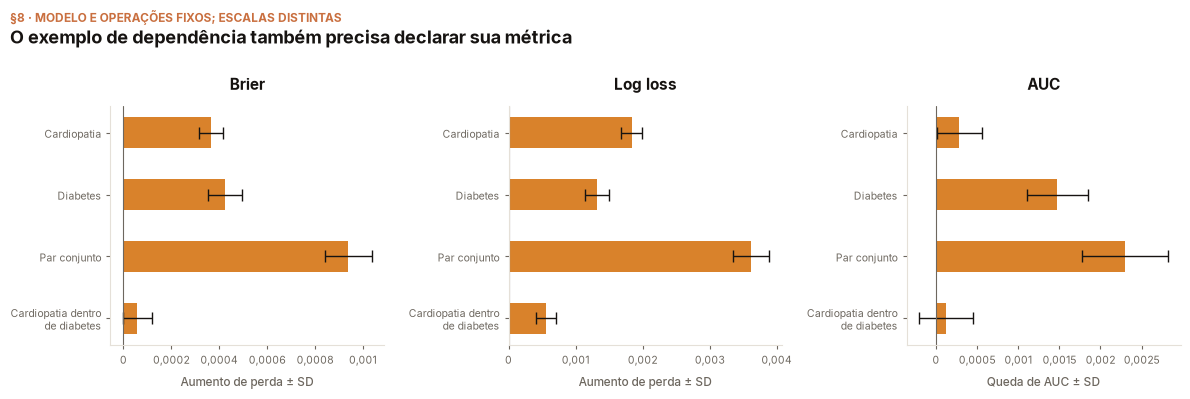

Primeira permutação global: escores conferidos com nova previsão nas três métricas.


Modelo, fichas e alvos preservados durante toda a comparação: True
Janela didática: médias destas fichas, sem generalização para o teste.
    estado      brier    logloss        auc
  Original 0,31962453 0,89476575 0,50000000
       Age 0,31170574 0,87046091 0,56250000
Low oxygen 0,30386299 0,85034903 0,56250000
A animação continua usando a média do teste completo em todas as permutações.
A evidência agregada completa foi gerada fora da árvore versionada.


In [12]:
# Recompute the end-of-lecture dependence example, preserving its exact orders.
# Individual marginal traces already have all scores in the original record.
dependence_metrics = []
for key, columns, selected_orders in [("joint", pair, orders), ("within", "cardiopati", restricted_orders)]:
    measured = {m: [] for m in MC.METRICS}
    for donor in selected_orders:
        changed = K.permutar_colunas(xe, columns, donor)
        prediction = np.asarray(model.predict_proba(changed)[:,1], dtype=np.float64)
        for metric, score in P.scores(ye,prediction).items():
            measured[metric].append(score)
    np.testing.assert_allclose(measured["brier"], actual_diagnostics[key], rtol=0,atol=1e-15)
    label = next(r["label"] for r in PUBLIC["dependence"]["results"] if r["key"]==key)
    dependence_metrics.append({"key":key,"label":label,"metrics":{
        m: MC.summarise_values(measured[m], comparison["original"][m], m) for m in MC.METRICS}})
for feature in ("cardiopati", "diabetes"):
    row=by_feature[feature]
    dependence_metrics.append({"key":feature,"label":row["label"],"metrics":row["metrics"]})
dependence_metrics.sort(key=lambda row:["cardiopati","diabetes","joint","within"].index(row["key"]))
comparison["dependence"] = dependence_metrics
print("Exemplo final: mesmas operações e mesmas ordens; mudamos apenas o escore.")
print(SP.tabela(pd.DataFrame([{"operação":row["label"],"métrica":MC.LABELS[m],
    "diferença orientada":row["metrics"][m]["importance_mean"],"SD":row["metrics"][m]["importance_sd"],
    "média após":row["metrics"][m]["after_mean"]}
    for row in dependence_metrics for m in MC.METRICS]),casas=8))

fig,axes=plt.subplots(1,3,figsize=SP.FAIXA)
for ax,metric in zip(axes,MC.METRICS):
    means=[row["metrics"][metric]["importance_mean"] for row in dependence_metrics]
    deviations=[row["metrics"][metric]["importance_sd"] for row in dependence_metrics]
    ax.barh(range(4),means,color=SP.AMBAR,height=.5)
    ax.errorbar(means,range(4),xerr=deviations,fmt="none",ecolor=SP.ESCURO,capsize=4,linewidth=1)
    ax.axvline(0,color=SP.CINZA,linewidth=.8)
    ax.set_yticks(range(4),["Cardiopatia","Diabetes","Par conjunto","Cardiopatia dentro\nde diabetes"])
    ax.invert_yaxis()
    ax.set_title(MC.LABELS[metric])
    ax.set_xlabel("Aumento de perda ± SD" if metric!="auc" else "Queda de AUC ± SD")
    ax.grid(axis="y",visible=False)
SP.titulo(fig,"O exemplo de dependência também precisa declarar sua métrica","§8 · modelo e operações fixos; escalas distintas")
SP.salvar(fig,"metricas-dependencia")
display(fig)
plt.close(fig)

# Check a real full-test prediction for each displayed single-column round.
for feature in ("idade_anos","saturacao"):
    changed=K.permutar_colunas(xe,feature,orders[0])
    scores=P.scores(ye,model.predict_proba(changed)[:,1])
    for metric in MC.METRICS:
        np.testing.assert_allclose(scores[metric],by_feature[feature]["metrics"][metric]["first_after"],rtol=0,atol=5e-5)
print("Primeira permutação global: escores conferidos com nova previsão nas três métricas.")
pd.testing.assert_frame_equal(xe,original_x)
np.testing.assert_array_equal(ye,original_y)
assert bytes(model.get_booster().save_raw())==model_snapshot
print("Modelo, fichas e alvos preservados durante toda a comparação:", True)

# The eight visible receivers are a teaching window, never a PFI estimate.
window_metrics=[]
for label,probability in [("Original",case_p_original)]+[(r["label"],case_table["p_after_"+r["cell"]].to_numpy()) for r in case_rounds]:
    measured=P.scores(case_y,probability)
    window_metrics.append({"estado":label,**measured})
comparison["teaching_window_scores"]=window_metrics
print("Janela didática: médias destas fichas, sem generalização para o teste.")
print(SP.tabela(pd.DataFrame(window_metrics),casas=8))
print("A animação continua usando a média do teste completo em todas as permutações.")

metric_output=WORK/"figures_generated/pfi_metric_comparison.json"
metric_output.write_text(json.dumps(comparison,ensure_ascii=False,indent=2,allow_nan=False)+"\n")
print("A evidência agregada completa foi gerada fora da árvore versionada.")


**O que olhar.** AUC avalia ordenação entre registros com desfechos distintos e não fornece uma perda por ficha. Log loss conserva a narrativa da probabilidade atribuída ao desfecho ocorrido, seguida da média. Para a aula seguir o exemplo de classificação de Molnar, podemos escolher log loss por essa razão didática; não por deixar o ranking mais favorável. Curvas de calibração continuam necessárias para avaliar calibração especificamente.


## Fechamento — informação perdida, desempenho alterado

Fixar o modelo, alterar uma fonte de informação e medir a alteração no erro é
 o experimento de PFI. Sua interpretação precisa trazer o preditor, a métrica,
 a avaliação, o mecanismo de permutação e a incerteza que de fato foi medida.

[Internals](pfi_internals.ipynb) confere o mecanismo contra um oráculo independente
 e a implementação da biblioteca. A ficha da base e a seleção permanecem no
 módulo 00, sem duplicação da amostra ou novo ajuste de seleção.

**Referências**

- Molnar, *Interpretable Machine Learning*, [cap. 23 — Permutation Feature Importance](https://christophm.github.io/interpretable-ml-book/feature-importance.html): livro da disciplina, interpretação e subgrupos.
- Breiman (2001), [Random Forests](https://doi.org/10.1023/A:1010933404324): origem da importância por permutação.
- Molnar et al. (2020), [Model-agnostic Feature Importance and Effects with Dependent Features — A Conditional Subgroup Approach](https://arxiv.org/abs/2006.04628): procedimento por subgrupos e seus condicionamentos.
- scikit-learn, [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html): algoritmo, métrica e dependência.
- Raschka, [Feature Selection — aula original](https://sebastianraschka.com/pdf/lecture-notes/stat451fs21/13_feat-sele__slides.pdf): sequência conceitual adaptada, sem redistribuição das páginas originais.
- Base e modelo: [módulo 00](../../00-dataset/README.md), [MODEL.md](../../00-dataset/MODEL.md), [SELECTION.md](../../00-dataset/SELECTION.md) e [registro PFI](../../00-dataset/gold/pfi_ranking.json).